In [1]:
from scipy import stats

x = [1, 2, 3, 4, 5, 6, 7]
y = [2, 4, 5, 4, 5, 7, 8]

# 1. Pearson correlation (linear relationship, continuous normal data)
r, p_val = stats.pearsonr(x, y)

# 2. Spearman rank correlation (monotonic relationship, ordinal/non-normal data)
rho, p_val = stats.spearmanr(x, y)

# 3. Kendall's tau (ordinal association, good for small samples with ties)
tau, p_val = stats.kendalltau(x, y)

# 4. Simple Linear Regression
res = stats.linregress(x, y)
print(f"Slope: {res.slope}, Intercept: {res.intercept}, R-squared: {res.rvalue**2}")

Slope: 0.8571428571428571, Intercept: 1.5714285714285716, R-squared: 0.8571428571428571


Slope: 0.8571428571428571, Intercept: 1.5714285714285716, R-squared: 0.8571428571428571


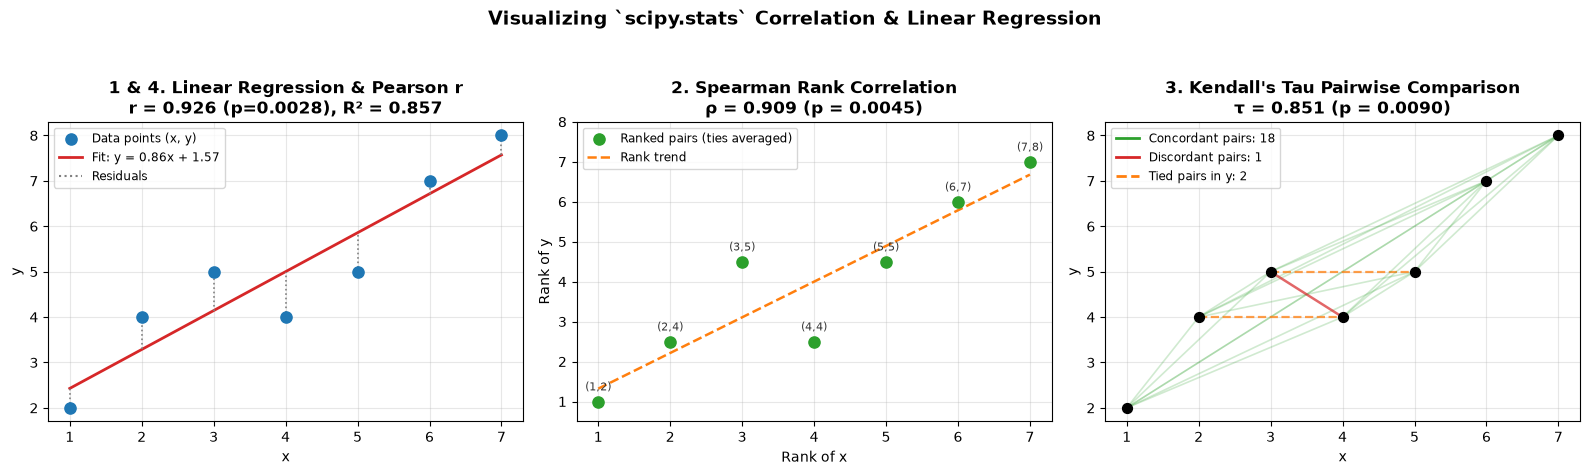

In [2]:
from scipy import stats

x = [1, 2, 3, 4, 5, 6, 7]
y = [2, 4, 5, 4, 5, 7, 8]

# 1. Pearson correlation (linear relationship, continuous normal data)
r, p_val = stats.pearsonr(x, y)
p_r = p_val

# 2. Spearman rank correlation (monotonic relationship, ordinal/non-normal data)
rho, p_val = stats.spearmanr(x, y)
p_rho = p_val

# 3. Kendall's tau (ordinal association, good for small samples with ties)
tau, p_val = stats.kendalltau(x, y)
p_tau = p_val

# 4. Simple Linear Regression
res = stats.linregress(x, y)
print(f"Slope: {res.slope}, Intercept: {res.intercept}, R-squared: {res.rvalue**2}")

# --- Visualization of the outputs above ---
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
fig.suptitle("Visualizing `scipy.stats` Correlation & Linear Regression", fontsize=14, fontweight='bold')

x_arr = np.array(x)
y_arr = np.array(y)
y_pred = res.intercept + res.slope * x_arr

# Panel 1: Simple Linear Regression & Pearson r
ax = axes[0]
ax.scatter(x_arr, y_arr, color='#1f77b4', s=65, zorder=4, label='Data points (x, y)')
ax.plot(x_arr, y_pred, color='#d62728', lw=2,
        label=f'Fit: y = {res.slope:.2f}x + {res.intercept:.2f}')
for xi, yi, ypi in zip(x_arr, y_arr, y_pred):
    ax.vlines(xi, min(yi, ypi), max(yi, ypi), color='gray', linestyle=':', lw=1.2)
ax.plot([], [], color='gray', linestyle=':', label='Residuals')
ax.set_title(f'1 & 4. Linear Regression & Pearson r\nr = {r:.3f} (p={p_r:.4f}), R² = {res.rvalue**2:.3f}', fontweight='bold')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.legend(loc='upper left', fontsize=8.5)
ax.grid(True, alpha=0.3)

# Panel 2: Spearman Rank Correlation (Rank(x) vs Rank(y))
ax = axes[1]
rx = stats.rankdata(x_arr)
ry = stats.rankdata(y_arr)
ax.scatter(rx, ry, color='#2ca02c', s=65, zorder=4, label='Ranked pairs (ties averaged)')
for i in range(len(x)):
    ax.annotate(f'({x[i]},{y[i]})', (rx[i], ry[i]), textcoords="offset points", xytext=(0, 8),
                ha='center', fontsize=8, color='#333')
slope_r, intercept_r, _, _, _ = stats.linregress(rx, ry)
ax.plot(rx, intercept_r + slope_r * rx, color='#ff7f0e', linestyle='--', lw=1.8, label='Rank trend')
ax.set_title(f'2. Spearman Rank Correlation\nρ = {rho:.3f} (p = {p_rho:.4f})', fontweight='bold')
ax.set_xlabel('Rank of x')
ax.set_ylabel('Rank of y')
ax.set_ylim(0.5, 8)
ax.legend(loc='upper left', fontsize=8.5)
ax.grid(True, alpha=0.3)

# Panel 3: Kendall's Tau (Concordant vs Discordant Pairs)
ax = axes[2]
conc, disc, ties = 0, 0, 0
for i in range(len(x)):
    for j in range(i + 1, len(x)):
        dx = x[j] - x[i]
        dy = y[j] - y[i]
        if dx * dy > 0:
            conc += 1
            ax.plot([x[i], x[j]], [y[i], y[j]], color='#2ca02c', alpha=0.22, lw=1.2)
        elif dx * dy < 0:
            disc += 1
            ax.plot([x[i], x[j]], [y[i], y[j]], color='#d62728', alpha=0.7, lw=1.8)
        else:
            ties += 1
            ax.plot([x[i], x[j]], [y[i], y[j]], color='#ff7f0e', linestyle='--', alpha=0.75, lw=1.6)

ax.scatter(x_arr, y_arr, color='black', s=50, zorder=5)
ax.plot([], [], color='#2ca02c', lw=2, label=f'Concordant pairs: {conc}')
ax.plot([], [], color='#d62728', lw=2, label=f'Discordant pairs: {disc}')
ax.plot([], [], color='#ff7f0e', linestyle='--', lw=2, label=f'Tied pairs in y: {ties}')
ax.set_title(f"3. Kendall's Tau Pairwise Comparison\nτ = {tau:.3f} (p = {p_tau:.4f})", fontweight='bold')
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.legend(loc='upper left', fontsize=8.5)
ax.grid(True, alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()